# CSVファイルの操作

## CSVファイルとは

CSV（Comma-Separated Values）ファイルは、表形式のデータを、項目ごとに区切ってテキストとして保存したファイルです。

一般に、1行が表の1行に対応し、各項目はカンマ（,）で区切られます。

例えば、次のようなデータです。先頭行には、各列の内容を示す見出し（ヘッダー）が含まれることがありますが、ヘッダーを付けなければならないという決まりはありません。

```
惑星名,英語名,直径(km),太陽からの平均距離(億km)
水星,Mercury,4879,0.58
金星,Venus,12104,1.08
地球,Earth,12742,1.50
火星,Mars,6779,2.28
木星,Jupiter,139820,7.79
土星,Saturn,116460,14.3
天王星,Uranus,50724,28.7
海王星,Neptune,49244,45.0
```
上の例では、先頭行の「惑星名」「英語名」「直径(km)」「太陽からの平均距離(億km)」がヘッダーにあたります。ヘッダーがあると、各列のデータが何を表しているのかを把握しやすくなります。

CSVファイルは、データをテキストとして保存するため、Excelなどの表計算ソフトだけでなく、さまざまなプログラムやシステムで利用できます。

なお、CSVは「カンマで区切られた値」という意味ですが、実際には、タブやセミコロンなど、カンマ以外の文字を区切り文字として使用する形式もあります。また、日本語を含むCSVファイルでは、UTF-8やShift-JIS（CP932）など、使用されている文字コードにも注意する必要があります。

## Python で CSVファイルを操作する意義

CSVファイルは、科学技術データだけでなく、ビジネスデータやアンケート結果など、大量の表形式データを扱う場合に広く利用されています。しかし、大量のデータを人が一つずつ確認したり計算したりするのは大変です。

Pythonを利用すると、CSVファイルからデータを読み込み、必要なデータを取り出して計算したり、条件に合うデータを検索したり、処理結果を別のファイルに保存したりする作業を自動化できます。

例えば、気象庁からダウンロードしたCSVファイルから気温のデータを読み込み、平均気温を計算したり、気温が30℃以上の日だけを取り出したりすることができます。

PythonにはCSVファイルを扱うための **csvモジュール** が用意されています。csv.reader() を利用すると、CSVファイルのデータを1行ずつ読み込み、各行をリストとして扱うことができます。

ここでは、まずcsvモジュールを利用したCSVファイルの基本的な読み込み方を学び、CSVに含まれるデータの取り出しや処理について学習します。
そして、 CSVファイルの作成についても習得します。

## CSV形式のファイルを入手（気象庁の気象データ）

[気象庁からダウンロードした気象データ](https://drive.google.com/file/d/1GkTyCAwg618Lzni7bCMlwOZaiyNYKc1q/view?usp=sharing)

上のデータは、次の手順で入手した、大阪府の最近１年の気象データです。

* 検索エンジンで「過去の気象データ・ダウンロード」で検索して、気象庁の「過去の気象データ・ダウンロード」サイトを開く。

1. 「地点を選ぶ」メニューで、地図の「大阪府」をクリックして、さらに大阪府の地図の中の「大阪」をクリックしてチェックが入るようにする
2. 「項目を選ぶ」メニューで、次の順番で項目を選択
    - データの種類：「日別値」
    - 過去の平均値との比較オプション： チェックを入れない
    - 「気温」タブ：「日最高気温」「日最低気温」
    - 「降水」タブ：「降水量の日合計」
    - 「雲量/天気」タブ： 「日平均雲量」「天気概況（昼）」「天気概況（夜）」
3. 「期間を選ぶ」メニューで、「最近１年」をクリック
4. 「表示オプションを選ぶ」メニューはデフォルトの設定のまま

* オレンジ色の「CSVファイルをダウンロード」ボタンを押す。

　　ダウンロードされるファイル名： data.csv　　漢字コード： Shift-JIS(CP932)

## CSVファイルの確認

ダウンロードされたファイルをメモ帳で開いて内容を確認してみよう。

メモ帳のウインドウ下のステータスバーの右端に、改行コードと文字コードが示されています。

* 改行コードには CR と LF があり、画面の表示では１つの改行を CR + LF の２つのコードの組で示す方式であることがわかります。
* 文字コードとして表示されるラベルとしては、「UTF-8」「ANSI」「Shift-JIS」などがあります。
    - UTF-8 は世界中で使われている標準的な文字コード UTF-8 のこと
    - ファイルの中身に漢字があってメモ帳の表示が 「ANSI」であれば、文字コードは CP932 （Windows のために拡張された Shift-JIS）というコードです。この場合、文字コードは Shift-JIS または CP932 として扱います。

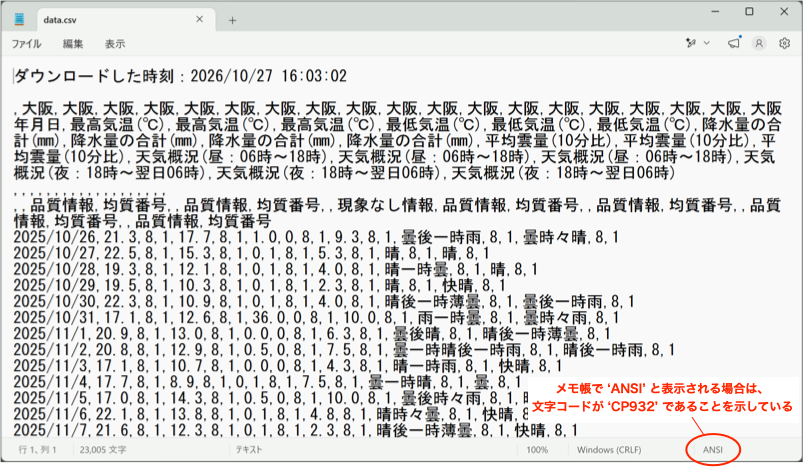

また、この CSV ファイルを表計算ソフトで開くと、次のように表示されます。

CSVファイルは、表計算ソフトで開くと、データが行と列に並んだ下のような表のように示されるものとイメージしておきましょう。

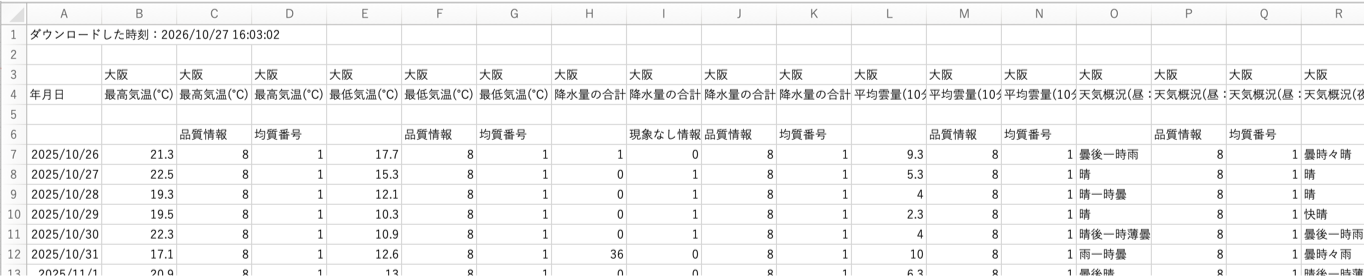

なお、気象庁からダウンロードしたデータの中で、「品質情報」というのは、そのデータ値が、どの程度の状態のデータなのかを示す情報で、８は正常であることを示しています。

また、「均質番号」は、観測環境などが変化したことによって、データの性質が変わっていないかを区別するための番号で、同じ番号であれば同一条件（同じ場所、同じ測定機器、同じ方法 など）での計測結果であることを示しています。

表計算ソフトでの表示状況をみるとわかるように、CSVデータの始めの数行は、
* １行目： ダウンロードした時刻
* ２行目： 空行
* ３行目： 見出しの一部（４行目とセット）
* ４行目： 見出しの本体
* ５行目： 見出しの一部（６行目とセット）
* ６行目： 見出しの一部
* ７行目以降： データの本体

となっていることがわかります。

**このファイルを Google Colab のフォルダにアップロードしましょう。**

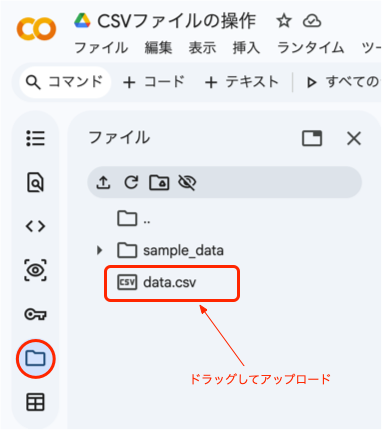

## CSVファイルの内容を Python から読み込む方法

CSVファイルの内容を Python を使って読み込む場合、定型的な使い方があり、CSVファイルの内容に合わせてそれをアレンジして使います。その流れを示します。

1. 組み込みモジュールの csv を使うので、まず **csvモジュールをインポート** します。

2. ファイルのオープンとクローズは、一般的なファイル処理と同じで、 with open() も利用できます。ファイルを開いた際には、 **ファイルオブジェクトを獲得** しておきます。漢字がファイルの内容に含まれる場合は、encoding引数で適切な文字コード（'utf-8' や 'cp932' など）を指定します。

3. CSV形式のファイルからデータを読み込むには、 **csv.reader()** を使って、CSVデータを行単位で読み込むための **リーダーオブジェクトを取得** します。

4. **next()** を使うと、リーダーオブジェクトから次の1行分のデータを取得できます。先頭行を見出しとして取得したり、不要な行を読み飛ばしたりする場合に利用できるので、適宜必要に応じて使います。

5. **for 文でリーダーオブジェクトを反復処理** すると、CSVファイルの **データを1行ずつリストとして取得** できます。 **各要素は文字列** です。



```
import csv                                      # (1) csv モジュールをインポート

with open("data.csv", encoding="utf-8", newline="") as f:   # (2) ファイルをオープンし、ファイルオブジェクトを取得
    reader = csv.reader(f)                      # (3) 行単位でデータを読み込むリーダーオブジェクトを取得

    header = next(reader)                       # (4) 必要に応じて先頭行（見出し）を取得、不要な行の読み飛ばし
    print(header[0], header[1], ... )           # リストとして見出し部分が入る

    for row in reader:                          # (5) リーダーオブジェクトの反復処理による行ごとのデータの取り出し
        print(row[0], row[1], ... )             # row はリスト（インデックスを使ってアクセス）
```



## CSVファイルのデータを読み込んで、そのまま表示するプログラム

ダウンロードした data.csv に対して csvモジュールの一般的な使い方を適用しよう。

csvファイルの内容が、１行ずつ、リストとして取り込めていることがわかります。

In [1]:
import csv                                  # csvモジュールを利用する準備

fname = 'data.csv'                          # ファイル名を変数 fname に代入

with open(fname, encoding='cp932', newline="") as f:    # with文を使ったファイルのオープン、変数 f にファイルオブジェクトが入る
    reader = csv.reader(f)                  # f の各行を順番に取り出すことのできるオブジェクトを作る
    for row in reader:                      # CSVファイルを1行ずつ読み取り、各行の項目を文字列のリストとして row に入れる
        print(row)                          # CSV の１行が１つのリストとして表示される

['ダウンロードした時刻：2026/10/27 16:03:02']
[]
['', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪', '大阪']
['年月日', '最高気温(℃)', '最高気温(℃)', '最高気温(℃)', '最低気温(℃)', '最低気温(℃)', '最低気温(℃)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '平均雲量(10分比)', '平均雲量(10分比)', '平均雲量(10分比)', '天気概況(昼：06時～18時)', '天気概況(昼：06時～18時)', '天気概況(昼：06時～18時)', '天気概況(夜：18時～翌日06時)', '天気概況(夜：18時～翌日06時)', '天気概況(夜：18時～翌日06時)']
['', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '']
['', '', '品質情報', '均質番号', '', '品質情報', '均質番号', '', '現象なし情報', '品質情報', '均質番号', '', '品質情報', '均質番号', '', '品質情報', '均質番号', '', '品質情報', '均質番号']
['2025/10/26', '21.3', '8', '1', '17.7', '8', '1', '1.0', '0', '8', '1', '9.3', '8', '1', '曇後一時雨', '8', '1', '曇時々晴', '8', '1']
['2025/10/27', '22.5', '8', '1', '15.3', '8', '1', '0', '1', '8', '1', '5.3', '8', '1', '晴', '8', '1', '晴', '8', '1']
['2025/10/28', '19.3', '8', '1', '12.1', '8', '1', '0', '1', '8', '1', '4.0', '8', '1', '晴

## （演習１）CSVファイルからデータを読み込んで必要なデータを表示するプログラムの作成

ダウンロードしたファイル data.csv から１年分の気象データを読み込んで、下記のデータを画面に表示するプログラムを作成しなさい。

表示させるデータ： 年月日、最高気温、最低気温、降水量の合計値、平均雲量、定期概況（昼）、天気概況（夜） … row のインデックス： 0, 1, 4, 7, 11, 14, 17

それに合わせて、最初に見出しも表示させなさい。

（方針）

* 最初の３行を読み飛ばすために、 next() を３回呼び出す。
* 次の１行を next() で読み込んで内容を変数に格納し、リストとして格納されるので、必要なところをインデックスで指定して、見出しを画面に表示させる。
* さらに２行を next() で読み飛ばす。
* データ部分について、リーダーオブジェクトの反復処理によって、必要なデータを画面に表示させる。

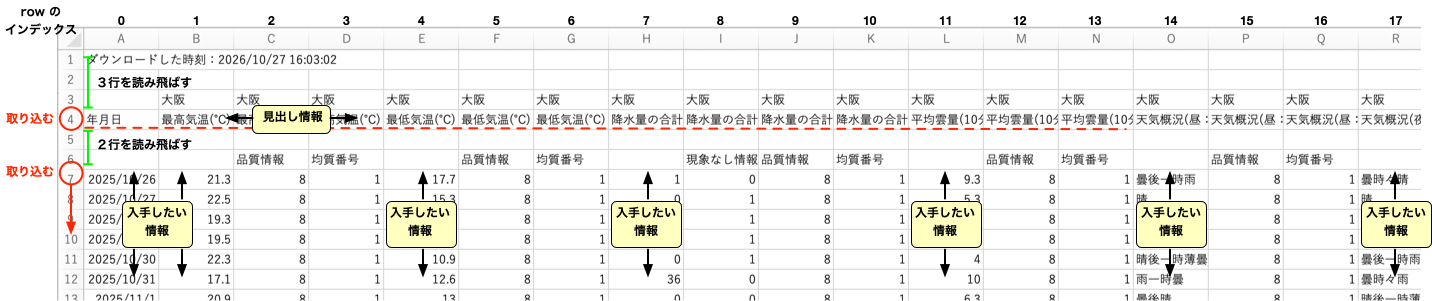

In [2]:
with open('data.csv')as f:print((a:=list(csv.reader(f)))[3],*a[6:],sep="\n")

['年月日', '最高気温(℃)', '最高気温(℃)', '最高気温(℃)', '最低気温(℃)', '最低気温(℃)', '最低気温(℃)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '降水量の合計(mm)', '平均雲量(10分比)', '平均雲量(10分比)', '平均雲量(10分比)', '天気概況(昼：06時～18時)', '天気概況(昼：06時～18時)', '天気概況(昼：06時～18時)', '天気概況(夜：18時～翌日06時)', '天気概況(夜：18時～翌日06時)', '天気概況(夜：18時～翌日06時)']
['2025/10/26', '21.3', '8', '1', '17.7', '8', '1', '1.0', '0', '8', '1', '9.3', '8', '1', '曇後一時雨', '8', '1', '曇時々晴', '8', '1']
['2025/10/27', '22.5', '8', '1', '15.3', '8', '1', '0', '1', '8', '1', '5.3', '8', '1', '晴', '8', '1', '晴', '8', '1']
['2025/10/28', '19.3', '8', '1', '12.1', '8', '1', '0', '1', '8', '1', '4.0', '8', '1', '晴一時曇', '8', '1', '晴', '8', '1']
['2025/10/29', '19.5', '8', '1', '10.3', '8', '1', '0', '1', '8', '1', '2.3', '8', '1', '晴', '8', '1', '快晴', '8', '1']
['2025/10/30', '22.3', '8', '1', '10.9', '8', '1', '0', '1', '8', '1', '4.0', '8', '1', '晴後一時薄曇', '8', '1', '曇後一時雨', '8', '1']
['2025/10/31', '17.1', '8', '1', '12.6', '8', '1', '36.0', '0', '8', '1', '10.0', '8', '1', '雨一時

## （演習２） 気象データ１年分から、年最高気温を抽出するプログラム

csvファイル data.csv を csvモジュールを使って読み込んで、データの中の最高気温を見つけて、その日付とともに最高気温を表示させなさい。

（ヒント）最高気温は、データを順に調べていって、それまでに見つけた最高気温よりも高い気温を見つけたら最高気温と日付を更新します。これまでの最高気温、日付は保存できるように変数を用意しておきます。また、気温の初期値は、ありえないくらい低い気温に設定しておきます。

In [3]:
with open('data.csv',encoding='cp932',newline="")as f:print(max(map(lambda x:float(x[1]),list(csv.reader(f))[6:])))

38.6


## Python から CSVファイルを書き込む方法

Python のデータを CSVファイルとして書き出す場合にも、定型的な使い方があります。その流れを示します。


1. ファイルのオープンとクローズは、一般的なファイル処理と同じです。with open() を利用でき、ファイルを開くと、ファイルを操作するためのファイルオブジェクトが得られます。書き出す場合は、ファイルを開くときに書き込みモード（"w"）を指定します。
漢字の内容が含まれる場合、適切に文字コードを encoding 引数として指定します。

2. CSV形式のファイルにデータを書き出すには、csv.writer() を使って、CSVデータを書き出すためのライターオブジェクトを取得します。

3-a. writerow() を使うと、リストなどのデータを1行分のCSVデータとして書き出せます。

3-b. writerows() を使うと、複数行分のデータをまとめて書き出せます。各行のデータは、リストなどの反復可能なオブジェクトで指定します。wirterows() の引数として、通常はリストのリストを渡します。

書き込む場合、 writerow(["2026/8/1", 36.2, ... ]) のように１行のデータをリストにして渡します。そのとき、数値を文字列に変換する必要はありません。

```
import csv

data = [
    ["氏名", "数学", "英語"],
    ["山田", 80, 75],
    ["佐藤", 90, 85],
]

with open("data.csv", "w", encoding="utf-8", newline="") as f:
    writer = csv.writer(f)
    writer.writerows(data)
```


## （演習３） 気象データ１年分から日々の最高気温、最低気温の情報だけを記した CSVファイルを作成

上記の１年分の気象データ data.csv を読み込んで、主要な情報だけを入れた別の CSVファイル smalldata.csv を作成します。

格納するデータ： 年月日、最高気温、最低気温 … row のインデックス： 0, 1, 4

（ヒント）読込むファイル、書き込むファイルを開いたうえで、リーダーオブジェクト、ライターオブジェクトを用意し、見出しの読込みと書込み、内容の読込みと書込みを行います。


In [4]:
fname = 'data.csv'
fname_w = 'smalldata.csv'

with open(fname, encoding='CP932', newline="") as f:                # 読込み用のファイルを開く
    reader = csv.reader(f)                              # 読込み用のオブジェクトを作成
    for i in range(6):                                  # ヘッダー部の６行のうち、４行目の内容を変数 header に取り込む
        if i == 3:
            header = next(reader)
        else:
            next(reader)
    with open(fname_w, 'w', encoding='utf-8', newline="") as fw:    # 書込み用のファイルを開く … 書込みモード 'w' を忘れない
        # 以下の手順で data.csv の内容から必要なところを smalldata.csv に書き込む
        # (1) 書込み用のオブジェクトを作成
        # (2) ヘッダー部分を書込み
        # (3) 読み込むたびに、必要なデータを書き込む
        



_IncompleteInputError: incomplete input (2550883496.py, line 17)

## CSV形式のデータを入手（文科省の大学データ）

文部科学省 学校コード
https://www.mext.go.jp/b_menu/toukei/mext_01087.html

「２．学校コード一覧」の「大学、短期大学、高騰専門学校」のところにある csv形式 200KB弱 をダウンロード（漢字コード： UTF-8）

ダウンロードしたファイルを Google Colab に入れて、名前を schools.csv に変更

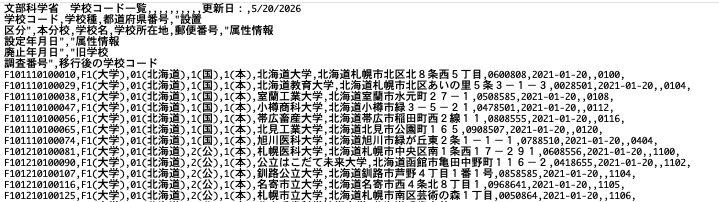

## （演習４）

上記の CSVファイルから、行の先頭の文字が 'F' である行について、大学名と住所（for文で得られたリストのインデックス5 と インデックス6 ）を表示させなさい。

## CSV形式の情報に含まれた住所情報をもとに地図にプロット



次の関数は、住所を引数として渡すと、その場所の経度・緯度情報をタプルで返す関数である。

'大阪府和泉市まなび野１−１' を引数として与えて、経度・緯度情報が得られることを確認しなさい。

In [ ]:
import requests

def get_lonlat(address):
    # API endpoint
    url = f"https://msearch.gsi.go.jp/address-search/AddressSearch?q={address}"

    response = requests.get(url)
    data = response.json()

    if data:
        # 返却される座標は [経度, 緯度] の順
        lon, lat = data[0]["geometry"]["coordinates"]
    else:
        lon, lat = -1, -1

    return (lon, lat)

In [ ]:
get_lonlat('大阪府和泉市まなび野１−１' )

## （演習５）

学校コード一覧の CSVファイルから、行の先頭の文字が 'F' である行について、大学名と住所（for文で得られたリストのインデックス5 と インデックス6 ）を得て、住所の中に '大阪府' の文字列が含まれるレコードに対して、次の条件を満たすCSVファイルを作成しなさい。

get_lonlat関数によって住所から緯度・経度情報を得て、大学名、住所、緯度、経度のそれぞれの情報からなる CSVファイル（下図のようなイメージ）を作成しなさい。

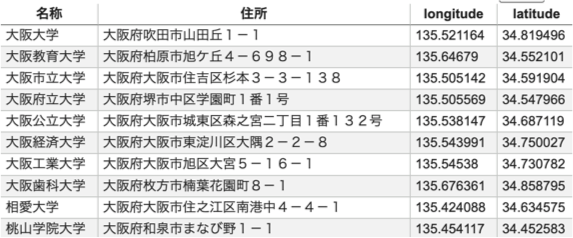

In [ ]:
import csv

fname = "schools.csv"        # 入力ファイル
fname_w = "univ.csv"         # 作成するファイル

with open(fname, encoding='utf8', newline="") as f:
    reader = csv.reader(f)
    with open(fname_w, 'w', encoding='utf-8', newline="") as fw:
        writer = csv.writer(fw)
        header =['名称', '住所', 'longitude', 'latitude']
        writer.writerow(header)
        for row in reader:
            if row[0][0] == 'F':
                name = row[5]
                address = row[6]
                if '大阪府' in address:
                    lon, lat = get_lonlat(address)
                    writer.writerow([name, address, lon, lat])
        # ヘッダーを書き込んでから、入力ファイル中の行の先頭の文字が 'F' である行で、かつ、住所が大阪府の学校について、名称/住所/経度/緯度 を書き出しなさい。





次に、 [GeoJSON.io](https://geojson.io/)
にアクセスして、画面右上の 'import' ボタンを押して、作成された CSV ファイルをデフォルトの設定でインポートすると地図に反映されます。